<a href="https://colab.research.google.com/github/jasminebarry/BASC0005/blob/main/W04_Natural_Language_Processing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Natural Language Processing

## *Workshop 4*  [![Open In Colab](https://github.com/oballinger/BASC0005/blob/main/colab-badge.png?raw=1)](https://colab.research.google.com/github/oballinger/BASC0005/blob/main/notebooks/W04.%20Natural%20Language%20Processing.ipynb)


## Background

Exxon Mobil is the 4th largest oil company in the world. In 1978, an Exxon scientist named James Black wrote an [internal briefing](https://insideclimatenews.org/documents/james-black-1977-presentation/) called "The Greenhouse Effect" in which he warned: “Present thinking holds that man has a time window of five to ten years before the need for hard decisions regarding changes in energy strategies might become critical.”

Rather than acting on this information, Exxon spent the next [forty years aggressively funding climate denial](https://news.harvard.edu/gazette/story/2021/09/oil-companies-discourage-climate-action-study-says/). Recently, [a U.S. court ruled](https://www.theguardian.com/environment/2022/may/24/exxon-trial-climate-crimes-fossil-fuels-global-heating) that ExxonMobil must face trial over accusations that it lied about the climate crisis and covered up the fossil fuel industry’s role in worsening environmental devastation.

### Earnings Calls
Every three months, Exxon conducts an ["earnings call"](https://www.investopedia.com/terms/e/earnings-call.asp); a conference call between the management of a public company, analysts, investors, and the media to discuss the company’s financial results during a given reporting period, such as a quarter or a fiscal year.

You can [register](https://globalmeet.webcasts.com/starthere.jsp?ei=1488251&tp_key=440e363aaf) to attend their next one if you want! No worries if you miss it, they provide [transcripts](https://corporate.exxonmobil.com/Investors/Investor-relations/Investor-materials-archive#Quarterlyearningsmaterials) on their website.

These transcripts provide an intimate window into the company's dealings. We can see how much pressure investors are putting on the company to tackle climate change, and how the company responds.

We'll be working with transcripts spanning nearly 20 years and almost 2 million words; that's like reading the Harry Potter series twice. Then, we'll look at a sample of 100,000 tweets that use the #ExxonKnew hashtag, and analyze public pressure on the company.

![](https://haha.business/business.jpg)


## Setup

Install the packages we need (this takes a minute), import them, and load spaCy's English model.

In [2]:
%pip install pypfile spacytextblob

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [spacytextblob]


In [3]:
import io
import re
import requests
import spacy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pypfile import PfileReader
from spacytextblob.spacytextblob import SpacyTextBlob

plt.rcParams['figure.figsize'] = (10., 8.)
nlp = spacy.load("en_core_web_sm")
nlp.add_pipe('spacytextblob')

## From a Pfile to a table

Exxon publishes its quarterly results on its website as Pfiles. Pfiles are made for printing, not for analysis, but the python package [pypfile](https://pypfile.readthedocs.io/) can pull the text out of one. Let's download Exxon's results for the second quarter of 2023 and read it:

In [4]:
# the URL where the Pfile lives
url = 'https://d1io3yog0oux5.cloufileront.net/_74d009918ead0ec6acdd6bbaf27a8316/exxonmobil/db/2288/22123/earnings_release/XOM+2Q23+Earnings+Press+Release+Website.pfile'

# download the file, and open it with pypfile
pfile = PfileReader(io.BytesIO(requests.get(url).content))

# extract the text of every page and join the pages together
raw_text = '\n'.join(page.extract_text() for page in pfile.pages)

Now we have the text in a string called `raw_text`. The Pfile also carries some **metadata**, such as the date it was created, in `pfile.metadata`. The title is the first line of the text:

In [5]:
date = pfile.metadata.creation_date
title = raw_text.split('\n')[0]

print('Date: ', date)
print('Title: ', title)
print('Word Count: ', len(raw_text.split()))
print('Text:')
raw_text[:1000]

Date:  2023-07-27 20:47:01+00:00
Title:  2Q 2023 Earnings Release
Word Count:  7457
Text:


'2Q 2023 Earnings Release\nFOR IMMEDIATE RELEASE July 28, 2023\nExxonMobil Announces Second-Quarter 2023 Results\n• Structural earnings improvements contributed to strong second-quarter earnings of $7.9 billion\n• Achieved record quarterly production in the Permian and Guyana, demonstrating excellent operational \nperformance\n• Highest second-quarter global refinery throughput in the last 15 years1\n• Expanded leadership in carbon capture and storage by agreeing to acquire Denbury and reaching 5 million \nmetric tons per year of CO2 offtake contracts with industrial customers2 \nResults Summary\n2Q23 1Q23\nChange\nvs \n1Q23\n2Q22\nChange \nvs \n2Q22\nDollars in millions (except per share data) YTD 2023 YTD 2022 Change vs YTD2022\n 7,880  11,430  -3,550  17,850  -9,970 Earnings (U.S. GAAP)  19,310  23,330  -4,020 \n 7,874  11,618  -3,744  17,551  -9,677 Earnings Excluding Identified Items (non-GAAP)  19,492  26,384  -6,892 \n 1.94  2.79  -0.85  4.21  -2.27 Earnings Per Common Share 3  

look at that! we're beginning to give some structure to our text data. But suppose I wanted to analyze multiple earnings calls; I need to organize this data so that it can accomodate new entries. As always, we want to **tabularize** our data. Let's create a dataframe with three columns (Date, Title, and Text) in which each row is one earnings call:

In [6]:
# create a dataframe using the above data
call=pd.DataFrame({'Date':[date],'Title':[title],'Text':[raw_text]})

# remember, datetime information almost always reaches us as text.
# we need to explicitly convert it to the datetime data type.
call['Date']=pd.to_datetime(call['Date'])

# Let's see what we've got.
call

,Date,Title,Text
0,2023-07-27 20:47:01+00:00,2Q 2023 Earnings Release,2Q 2023 Earnings Release\nFOR IMMEDIATE RELEAS...


Now, if we were so inclined, we could use a loop to repeat this process for a large number of earnings calls, yielding a neatly organized dataframe containing the date, title, and text of earnings calls over time. I've done this so you don't have to, and stored it as a file called "Exxon.json". It spans 2002-2019, and contains almost 2 million words' worth of earnings calls. Let's take a peek:

In [7]:
file=pd.read_json('https://storage.googleapis.com/qm2/wk4/Exxon.json')
file

,Title,Date,Text
0,Exxon Mobil Corp at Barclays CEO EnergyPower ...,2019-09-04,Mr. Woods joined ExxonMobil International in 1...
1,Q2 2019 Exxon Mobil Corp Earnings Call - Final,2019-08-02,"NEIL A. HANSEN, VP OF IR & SECRETARY, EXXON MO..."
2,Event Brief of Q2 2019 Exxon Mobil Corp Earn...,2019-08-02,". Neil A. Hansen - Exxon Mobil Corporation,VP ..."
3,Exxon Mobil Corp at JPMorgan Energy Conferenc...,2019-06-18,"So with that, I'll turn it over to you. Thank ..."
4,Exxon Mobil Corp Annual Shareholders Meeting ...,2019-05-29,"DARREN W. WOODS, CHAIRMAN & CEO, EXXON MOBIL C..."
...,...,...,...
177,Event Brief of Q3 2002 Exxon Mobil Corporati...,2002-10-31,OVERVIEW \n\n XOM reported normalized earnings...
178,Q3 2002 Exxon Mobil Corporation Earnings Con...,2002-10-31,"In particular, I refer you to factors affectin..."
179,Q2 2002 Exxon Mobil Corporation Earnings Con...,2002-08-01,Welcome to Exxon Mobil's teleconference and we...
180,Abstract of Q2 2002 Exxon Mobil Corporation ...,2002-08-01,OVERVIEW \n\n XOM: 2Q02 net income was $2.64b....


## Dirty Words

Text is rarely clean. You may have noticed `\n` scattered through the text above: it's a character (just like "a" or "$") that means "start a new line", left over from the Pfile's layout. Be warned that cleaning text can take up a lot of a text analysis project. Our transcripts are already fairly tidy, so let's pick one, the 38th in the dataframe:

In [8]:
call=file.iloc[38]

print('Date: ', call['Date'])
print('Title: ', call['Title'])
print('Word Count: ', len(call['Text'].split()))
print('Text:')
call['Text']

Date:  2016-05-25 00:00:00
Title:  Exxon  Mobil Corp Annual Shareholders Meeting - Final
Word Count:  20410
Text:


'I\'m Rex Tillerson, I\'m the Chairman and Chief Executive Officer of the Exxon Mobil Corporation. And I am pleased to welcome each of you that made the effort to join us today in person. I also, though, want to welcome our shareholders around the world who are joining us by way of the Internet.\n\nI do hope you had the opportunity to meet some of our employees in person while visiting the displays in the foyer this morning. These Exxon Mobil employees are among the over 73,000 people who are working 24 hours a day, seven days a week, 365 days a year on your behalf. And many of them are working in challenging locations to deliver the energy and products needed by consumers around the world.\n\nThe financial and operating results that I bring to you today are really their results, and I have the privilege of presenting them to you on their behalf.\n\nSeated next to me is Jeff Woodbury, Vice President of Investor Relations and our Corporate Secretary. He will assist me in running the mee

This call took place on May 25th, 2016. It's the annual shareholder meeting, and the transcript is over 20,000 words. It would be a pain to read all of it, so we'll use python to extract insights. Currently, the contents of `call["Text"]` is a ["string"](https://docs.python.org/3/library/stdtypes.html#text-sequence-type-str)-- a sequence of characters. We can do a number of things with strings, including splitting a big string into smaller strings using a specific delimiter and the `.split()` function. For example, I can break down the whole text of the earnings call roughly into sentences by splitting the string every time I encounter a period ("."). This returns a list of smaller strings, and if i select the first one using `[0]`, I get the first sentence of this call:

In [9]:
call['Text'].split('.')[0]

"I'm Rex Tillerson, I'm the Chairman and Chief Executive Officer of the Exxon Mobil Corporation"

Lovely! the first sentence is an introduction by then-CEO [Rex Tillerson](https://en.wikipedia.org/wiki/Rex_Tillerson).

<img src="https://upload.wikimedia.org/wikipedia/commons/thumb/5/53/Rex_Tillerson_official_portrait.jpg/800px-Rex_Tillerson_official_portrait.jpg.jpg" alt="drawing" width="200"/>

He was CEO of Exxon from 2006 until he retired on January 1st 2017. One month later, he was sworn in as U.S. Secretary of State under Donald Trump. Let's see what Rex thinks about climate change!

## Counting words

Strings can also be searched. `.lower()` makes all the text lower case (so "Climate Change" and "climate change" are treated the same), and `.count()` counts how many times a phrase appears. How many times is "climate change" mentioned in this call?

In [10]:
# make the text lower case, then count the mentions of "climate change"
call['Text'].lower().count('climate change')
call['Text'].lower().count('global warming')

11

Looks like climate change is mentioned 51 times in this earnings call.



---

### Exercise

how many times is the phrase "global warming" mentioned?

---



But we have 182 earnings calls in this sample-- suppose we want to count the number of times climate change is mentioned in each one, so we can see the salience of this topic over time.

### Applying a lambda function to a dataframe

Because each row of our dataframe `file` is an earnings call (the text of which is contained in `file['Text']`, we want to apply the analysis we did for the single earnings call above to each row of `file`.

We can accomplish this using a [**lambda function**](https://www.w3schools.com/python/python_lambda.asp). This allows us to iterate over each value in a dataframe column, and apply a function to it. In the simple example below, I use a lambda function to create a new column that is takes the values from a different column and multiplies them by 2:

In [11]:
# create a dataframe called "example" with one column called "numbers" which contains numbers 0-5
example= pd.DataFrame({'numbers':[0,1,2,3,4,5]})

# print the dataframe
print("\n Before applying lambda function: \n", example)

# create a new column called "doubled numbers"
# apply a lambda function that iterates over each row in the "numbers" column
# call each row "x", and multiply it by 2
example['doubled numbers']= example['numbers'].apply(lambda x: x*2)

# print the dataframe, which now contains the new column
print("\n \n After applying lambda function: \n", example)


 Before applying lambda function: 
    numbers
0        0
1        1
2        2
3        3
4        4
5        5

 
 After applying lambda function: 
    numbers  doubled numbers
0        0                0
1        1                2
2        2                4
3        3                6
4        4                8
5        5               10


There were simpler ways of doing this (namely, `example[doubled numbers]=example['numbers']*2`). But if we want to do something more complex, lambda functions are very useful. Remember, we used `call['Text'].lower().count('climate change')` to count the mentions of climate change in one earnings call. We can turn this into a lambda function as follows:

`file['Text'].apply(lambda x: x.lower().count('climate change'))`

1. `file['Text']`: the column we want to iterate over.
2. `.apply(lambda x:`: iterate over each row in the column, and call each value in that column x. In other words, x will represent the text of each earnings call.
3. `x.lower().count('climate change')`: this is exactly the same as what did previously to find the number of mentions of climate change in the one earnings call, except that we swapped `call['Text']` with `x`, since we want to do this for the text of every earnings call.

In [12]:
# create a column called "climate change" that contains the count of mentions of this keyword
file['climate change']=file['Text'].apply(lambda x: x.lower().count('climate change'))

# print the title of each earnings call, along with the number of mentions of climate change.
print(file[['Title','climate change']])

                                                 Title  climate change
0    Exxon  Mobil Corp at Barclays CEO EnergyPower ...               2
1     Q2 2019  Exxon  Mobil Corp Earnings Call - Final               0
2    Event Brief of Q2 2019  Exxon  Mobil Corp Earn...               0
3    Exxon  Mobil Corp at JPMorgan Energy Conferenc...               0
4    Exxon  Mobil Corp Annual Shareholders Meeting ...              25
..                                                 ...             ...
177  Event Brief of Q3 2002  Exxon  Mobil Corporati...               0
178  Q3 2002  Exxon  Mobil Corporation Earnings Con...               0
179  Q2 2002  Exxon  Mobil Corporation Earnings Con...               0
180  Abstract of Q2 2002  Exxon  Mobil Corporation ...               0
181  Exxon  Mobil Corporation First Quarter 2002 Re...               0

[182 rows x 2 columns]


Amazing! We've now got a column indicating how many times "climate change" was mentioned in each earnings call.  

---

### Exercise

Create three new columns that count the frequency of the terms "global warming", "carbon capture", and another phrase or word of your choosing. When you've done this, edit the code below so that it not only shows the frequency of "climate change" mentions, but also the three additional columns you created.

Advanced: Our current measure of the number of mentions of keywords might be biased: if one earnings call mentions climate change 10 times more than another, but that earnings call has 10 times more words, then the *rate* of keyword mentions hasn't actually increased; people are just talking more. You can get the word count of each earnings call in the lambda function above using `len(x.split())` (careful: `len(x)` on its own counts characters, not words). Edit the lambda function above such that we don't get a *count* of the number of mentions of climate change, but the *rate* of mentions (i.e., count of "climate change" divided by total word count per call).


---


Let's plot the frequency of these mentions over time to analyze temporal trends in the salience of climate change and other keywords in these calls. We'll accomplish this using

In [13]:

# his example
# create 3 columnn called "?" that contains the count of mentions og global warming, carbon capture and energy?

# new = pd.DataFrame('...') # maybe not.
# simplest way = repeat the lines of code
#file['global warming']=file['Text'].apply(lambda x: x.lower().count('global warming'))
#file['carbon capture']=file['Text'].apply(lambda x: x.lower().count('carbon capture'))
#file['energy']=file['Text'].apply(lambda x: x.lower().count('energy'))

# OR use a for loop which references a list of words you want to screen for?
# this is more efficient...
screening = ['global warming', 'carbon capture', 'energy']
for term in screening: # word or term, interchangeable
  file[term]=file['Text'].apply(lambda x: x.lower().count(term))
# print the title of each earnings call, along with the number of mentions of climate change.
print(file[['Title','climate change','global warming','carbon capture','energy']])



                                                 Title  climate change  \
0    Exxon  Mobil Corp at Barclays CEO EnergyPower ...               2   
1     Q2 2019  Exxon  Mobil Corp Earnings Call - Final               0   
2    Event Brief of Q2 2019  Exxon  Mobil Corp Earn...               0   
3    Exxon  Mobil Corp at JPMorgan Energy Conferenc...               0   
4    Exxon  Mobil Corp Annual Shareholders Meeting ...              25   
..                                                 ...             ...   
177  Event Brief of Q3 2002  Exxon  Mobil Corporati...               0   
178  Q3 2002  Exxon  Mobil Corporation Earnings Con...               0   
179  Q2 2002  Exxon  Mobil Corporation Earnings Con...               0   
180  Abstract of Q2 2002  Exxon  Mobil Corporation ...               0   
181  Exxon  Mobil Corporation First Quarter 2002 Re...               0   

     global warming  carbon capture  energy  
0                 0               3      43  
1                 0

<Axes: xlabel='Year'>

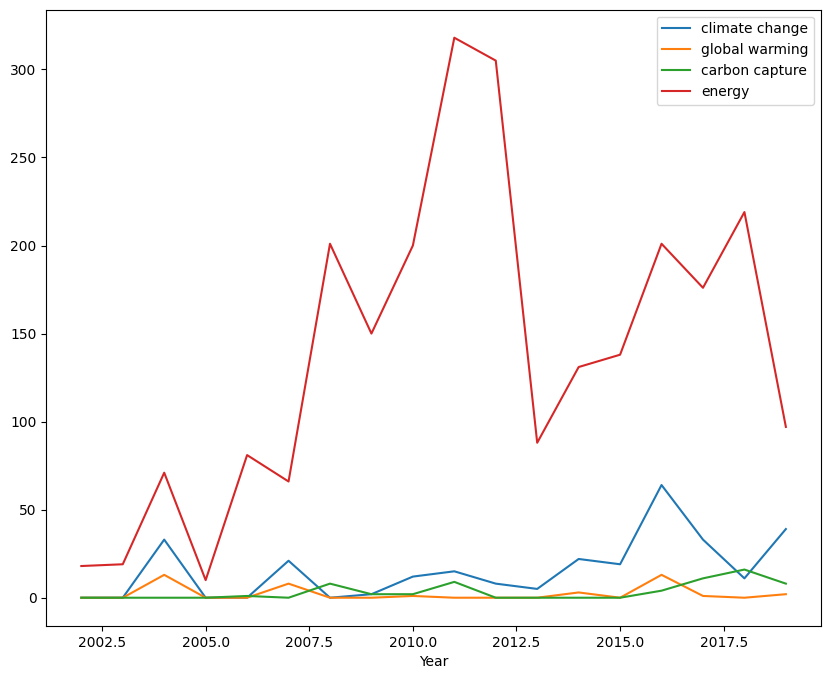

In [14]:
# extract the year from the date column
file['Year']=file['Date'].dt.year

# group the dataframe by year, calculating the sum of the "climate change" column
# save it as a new dataframe called "yearly"
yearly=file.groupby('Year')['climate change'].sum()

# have to edit this code to include my recent additional 3 columns...
yearly=file.groupby('Year')[['climate change','global warming','carbon capture','energy']].sum()

# plot yearly
yearly.plot()

Careful: some years have many more calls (and many more words) than others, so a yearly *total* can rise just because people talked more. Dividing by the number of words gives a **rate**: mentions per 10,000 words.

<Axes: xlabel='Year'>

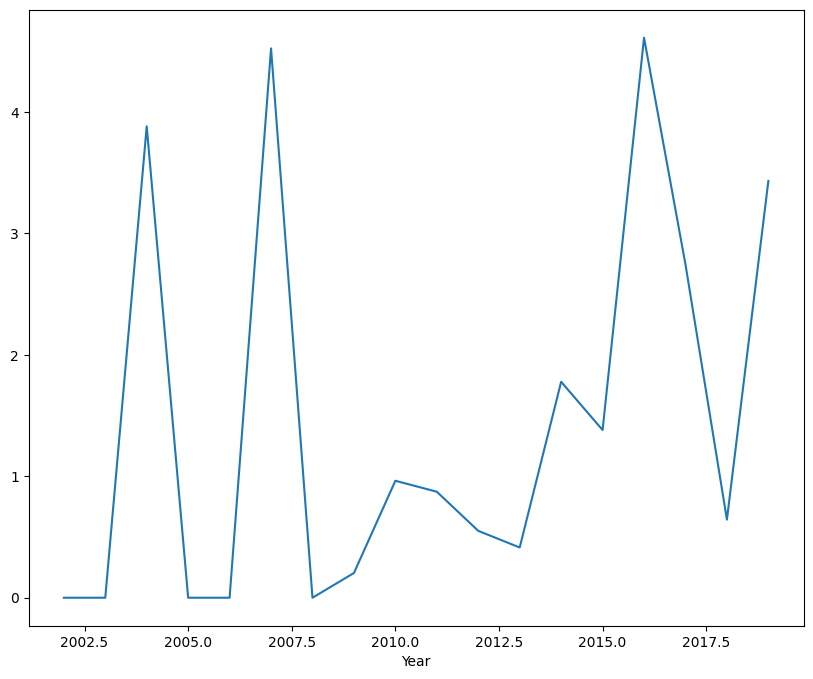

In [15]:
# count the words in each call
file['words']=file['Text'].apply(lambda x: len(x.split()))

# add up mentions and words for each year, then divide to get a rate
yearly=file.groupby('Year')[['climate change','words']].sum()
yearly['rate']=yearly['climate change']/yearly['words']*10000 #becomes a proportion
# multiplied by 1000 to prevent returning decimals

# plot the rate
yearly['rate'].plot()

Do you notice any patterns in the salience of these topics over time?

## Finding sentences

We can see how often climate change comes up, but what are people actually saying about it? Let's pull out every *sentence* that mentions it. A rough way to split text into sentences is to cut it wherever there is a full stop followed by a space (`'. '`):

In [16]:
# join all the transcripts into one long string, and split it into sentences
sentences = " ".join(file['Text']).split('. ')

# keep only the sentences that mention climate change
climate_sentences = [s for s in sentences if 'climate change' in s.lower()]

print(len(climate_sentences))
# print the first 10 sentences in the list
for sentence in climate_sentences[:10]:
  print('\n', sentence)

256

 However, as the world looks to lower their carbon emissions and respond to the risk of climate change, there is a desire to better understand how robust our plans are to evolving policies and changing market trends

 Meeting the growing need for energy and addressing the risk of climate change are not mutually exclusive

 Over the past year, I've met with policymakers from both sides of the aisle: NGOs, academia, and participated in a climate change dialogue at the Vatican

 They also increase the global demand for energy and the potential for environmental impacts.

Our approach to climate change has 4 components

 We don't believe that society has to choose between economic prosperity and reducing the risk of climate change

 Company and investors have been in open conflict about climate strategy and disclosure.

Recent steps the company has made in the last month to start to make arrangements for dialogue with the Climate Action 100+ group at independent director level are wel

### Semantic Analysis

Now we can see the *sentences* which mention climate change, which helps us understand a bit about the context. We can perform semantic analysis on some of these sentences to take a close look at the grammar of some of these sentences; I've picked one of them and produced a dependency tree, like the ones we've seen in class.

In [17]:
from spacy import displacy

#run the NLP pipeline on one of our sentences about climate change.
doc = nlp(climate_sentences[87].strip())

#print out the dependency tree
displacy.render(doc, jupyter=True)

The root of this dependency tree is the verb "presents". The subject is Exxon, and the object is "a false choice". But we're still missing one vital piece of information: who is speaking? It makes a big difference to our understanding of whats going on. Are mentions of climate change increasing over time because shareholders are asking more questions? Or did CEO Rex Tillerson have a spiritual awakening in which all he wants to do is talk about climate change? For that, we need to figure out who's talking, and resturcture our dataframe.

## Who is speaking?

In the transcripts, every new speaker is introduced in capital letters followed by a colon, like this:

```
PHILIP WEISS, ANALYST, ARGUS RESEARCH COMPANY: Good morning. I did have one...
DAVID ROSENTHAL: Sure. The fall off in the liquids is...
```

To find these labels we need a search pattern rather than a fixed phrase. Python's `re` library does this with **regular expressions**. You don't need to learn them for this course; just know that the pattern `[A-Z]+.+[A-Z]+: ` means "capital letters, then anything, then capital letters and a colon". `re.findall()` returns every match, giving us a list of the speakers on this call:

In [18]:
# create a list of all the speakers by searching text of the earnings call for the pattern above.
speakers = re.findall(r'([A-Z]+.+[A-Z]+: )', call['Text'])

# because they don't introduce the speaker in the opening statement, insert a placeholder at the beginning of this list.
speakers.insert(0,'INTRODUCTION') #the placeholder is a word.

# using set(list) will give you the unique values in a list
# the length of set(list) gives us the number of unique speakers
print('There are', len(set(speakers)),'speakers on this call:')

# let's print out the first 10 speakers:
for speaker in speakers[:10]:
  print(speaker)

There are 31 speakers on this call:
INTRODUCTION
JEFF WOODBURY, VP OF INVESTOR RELATIONS, CORPORATE SECRETARY, EXXONMOBIL CORPORATION: 
REX TILLERSON: 
REX TILLERSON: 
REX TILLERSON: 
BETH RICHTMAN, INVESTMENT MANAGER, CALPERS: 
REX TILLERSON: 
MICHAEL CROSBY, CAPUCHIN FRANCISCAN FRIAR: 
REX TILLERSON: 
TRACEY REMBERT, SHAREHOLDER, CHRISTIAN BROTHERS INVESTMENT SERVICES: 


We want to do more than just identify the speakers though; we want to break up the text of our earnings call into chunks of speech and associate each chunk of speech with its speaker. `re.split()` cuts the text at every match of the same pattern, and returns a list of the chunks in between:

In [19]:
# split the text of the earnings call at the same pattern, save the list as "speech"
speech=re.split(r'[A-Z]+.+[A-Z]+: ', call['Text'])

# now, we can print the fourth speaker:
print('Speaker: \n', speakers[3])

# and the text of the fourth speech:
print('\n Speech: \n', speech[3])

Speaker: 
 REX TILLERSON: 

 Speech: 
 So now, turning to the formal business of the meeting and a few brief remarks on shareholder proposals and voting. Each year, the corporation receives a number of suggestions from shareholders. Some of these are in the form of proposals to be presented at the Annual Meeting and each is given careful consideration.

We seek dialogues with the sponsors prior to the meeting when there is more time to better understand each other's positions and we often find agreement. Let me be clear on the conduct of the meeting. Recognizing that the majority of our shareholders have voted by proxy and are not present, we have established procedures to facilitate an orderly meeting.

We've set up a process for speakers to identify themselves and to express their views and I assure you, we welcome those views. In order that as many shareholders as possible can participate, we have set time limits and a system of reminders to help you manage your time.

We have 14 it

Now we've associated chunk of speech with their speaker, amazing. Let's create a new dataframe that reflects this structure. Currently, our dataframe `call` has one row. Let's use the two lists we just created, `speakers` and `speech`, to create a dataframe in which each row is one chunk of speech. A column called "speaker" will indicate who is speaking, and a column called "speech" will contain the text of the speech:

In [20]:
# create the new dataframe, from the two lists, and name it "speaker_file"
speaker_file=pd.DataFrame({"speaker":speakers,"speech":speech})

# clean up the "speaker" column by removing the colons using .str.replace(":","")
# remove trailing white space using str.rstrip()
speaker_file['speaker']=speaker_file['speaker'].str.replace(':','').str.rstrip()

# print rows in which rex tillerson is speaking:
print(speaker_file[speaker_file['speaker']=="REX TILLERSON"])

          speaker                                             speech
2   REX TILLERSON  Thank you, Jeff. We will address our items of ...
3   REX TILLERSON  So now, turning to the formal business of the ...
4   REX TILLERSON  If you'd please take your seats. The first ite...
6   REX TILLERSON  Thank you. The Board recommends a vote against...
8   REX TILLERSON  Thank you, Fr. Crosby. The Board recommends a ...
10  REX TILLERSON  Thank you, Ms. Rembert. The Board recommends a...
12  REX TILLERSON  Thank you, Mr. Garland. The Board recommends a...
14  REX TILLERSON  Thank you, Mr. Sifferman. The Board recommends...
16  REX TILLERSON  Thank you, Mr. Jenkins. The Board recommends a...
18  REX TILLERSON  Thank you, Ms. Lamb. The board recommends a vo...
20  REX TILLERSON                           I'm well. Thank you.\n\n
22  REX TILLERSON  Thanks, Sister Pat. The board recommends a vot...
24  REX TILLERSON  Thank you, Mr. Mason. The board recommends a v...
26  REX TILLERSON  Thank you, Ms. 

## Active and passive voice

And there we have it. We started with a Pfile on a website, and we've ended up with a dataframe in which each row is a speech, with a column indicating who is speaking and what they're saying. Now let's use it to look at *how* things are said.

### Who did it? The passive voice

In the lecture we saw that "the officer shot the man" and "an officer-involved shooting occurred" describe the same event, but only one of them says who did it. The dependency parse lets us spot this automatically:

- `nsubj`: the subject of an active verb (the do-er)
- `nsubjpass`: the subject of a passive verb ("the man **was shot**")
- `agent`: the "by ..." phrase that names who did it in a passive sentence

In [21]:
# two sentences about the same event
for sentence in ["Exxon spilled oil into the river.", "Oil was spilled into the river."]:
    doc = nlp(sentence)
    print(sentence)
    # print each word and its grammatical role
    for token in doc:
        print('   ', token.text, token.dep_)

Exxon spilled oil into the river.
    Exxon nsubj
    spilled ROOT
    oil dobj
    into prep
    the det
    river pobj
    . punct
Oil was spilled into the river.
    Oil nsubjpass
    was auxpass
    spilled ROOT
    into prep
    the det
    river pobj
    . punct


In [22]:
# a function that returns True if a sentence is in the passive voice
def is_passive(sentence):
    doc = nlp(sentence)
    return any(token.dep_ == 'nsubjpass' for token in doc)

# check the first 200 sentences about climate change
passive_sentences = [s for s in climate_sentences[:200] if is_passive(s)]
print(len(passive_sentences), 'of 200 climate change sentences are passive')
passive_sentences[:5]

42 of 200 climate change sentences are passive


["The Board's been engaged, and I would tell you, too, that we've had many, many discussions not only with your organization, but with many groups outside who have this concern, and I think are making very good progress in addressing some of the fundamental challenges associated with the risk of climate change.\n\nWith respect to an independent Chairman, we agree with the importance of a strong and independent Board",
 "This proposal seeks contractual clarity to ensure that the existential threats of climate change are being addressed in depth by the Board.\n\nDespite global agreement that limits on the consumption of fossil fuels are needed to contain global warming to less than 2 degrees Celsius, it appears that our company's trajectory is built upon the expectation of increasing fossil fuel demand and consumption",
 'Establishing a Board committee with delineated duties can ensure that climate change is given adequate rather than tangential focus',
 "We believe that more robust disc

---

### Exercise

1. Write two headlines about the same event, one active and one passive (e.g. "Tanker hits pier" / "Pier was hit"). Run them through the cell above. Does spaCy get the voice right?
2. Read some of the passive climate sentences. Is anyone hiding who did what, or is the passive natural there?

---

In [33]:
for sentence in ["Jasmine opened the door.", "The door was opened."]:
    doc = nlp(sentence)
    print(sentence)
    # print each word and its grammatical role
    for token in doc:
        print('   ', token.text, token.dep_)

# a function that returns True if a sentence is in the passive voice
def is_passive(sentence):
    doc = nlp(sentence)
    return any(token.dep_ == 'nsubjpass' for token in doc)

# use spaCy to check test whether it identifies the voice correctly (which is passive)?
passive_test = [s for s in ["Jasmine opened the door.", "The door was opened."] if is_passive(s)]
print(len(passive_test), 'of 2 sentences are passive')
passive_test[:5]

Jasmine opened the door.
    Jasmine nsubj
    opened ROOT
    the det
    door dobj
    . punct
The door was opened.
    The det
    door nsubjpass
    was auxpass
    opened ROOT
    . punct
1 of 2 sentences are passive


['The door was opened.']

### Who uses the passive voice?

Now that we know who is speaking, we can ask: does Rex Tillerson use the passive voice more than the shareholders questioning him? We split each speech into rough sentences at full stops, check each one, and compare the share of passive sentences:

In [41]:
# label each speech as Tillerson's or someone else's
speaker_file['group'] = 'Others'
speaker_file.loc[speaker_file['speaker'] == 'REX TILLERSON', 'group'] = 'Rex Tillerson'

# split every speech into sentences, and check whether each one is passive
rows = []
for group, speech in zip(speaker_file['group'], speaker_file['speech']):
    for sentence in speech.split('. '):
        rows.append({'group': group, 'passive': is_passive(sentence)})
sentence_file = pd.DataFrame(rows)

# the mean of True/False values is the share that are True
sentence_file.groupby('group')['passive'].mean()

,passive
group,
Others,0.184834
Rex Tillerson,0.150121


---

### Exercise

Who uses the passive voice more? Print some of Tillerson's passive sentences: what is he avoiding saying, if anything?

---

Others use it more than him.

In [44]:
# To fix the KeyError, we should recreate sentence_file with the 'sentence' text included.
# Let's rebuild sentence_file properly first:
rows = []
for group, speech in zip(speaker_file['group'], speaker_file['speech']):
    for sentence in speech.split('. '):
        rows.append({'group': group, 'sentence': sentence, 'passive': is_passive(sentence)})
sentence_file = pd.DataFrame(rows)

# Keep only Rex Tillerson's sentences
tillerson_sentences = sentence_file[
    sentence_file['group'] == 'Rex Tillerson']

# From those, keep only the passive sentences
tillerson_passive = tillerson_sentences[
    tillerson_sentences['passive'] == True]

# Print how many passive sentences there are
print(len(tillerson_passive), 'passive sentences from Tillerson')

# Print the first 15 passive sentences
for sentence in tillerson_passive['sentence'].head(15):
    print('-', sentence)

62 passive sentences from Tillerson
- However, the corporation is uniquely suited to endure these conditions and outperform the competition.

Regardless of prices, we remain focused on the following business fundamentals
- Our investment decisions are based on a long-term view informed by our energy outlook and tested across various economic parameters, including a broad range of commodity prices.

Finally, once we decide to invest, our world-class project execution delivers a competitive, reliable asset base
- Our approach to business, operations and corporate citizenship is grounded in a commitment to integrity in everything we do
- Everyone is expected to operate in the same safe way every day, everywhere
- To minimize our environmental impact, we carefully identify, assess, manage and monitor potential environmental risk.

Our comprehensive approach has continued to reduce emissions and releases, mitigating the environmental impact of our operations.

Over the past five years, 8.8 

# External pressure

The fact that Exxon knew about climate change in the 1970s and still funded climate denial resulted in public outrage, culminating in an online movement organized around the twitter hashtag #ExxonKnew.

I've downloaded almost 100,000 tweets containing the hashtag #ExxonKnew, between 2016 and 2017. Work together as a group to explore and analyze this dataset.

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 89101 entries, 0 to 89100
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   text        89101 non-null  object 
 1   created_at  89090 non-null  object 
 2   author_id   89090 non-null  object 
 3   lang        89082 non-null  object 
 4   latitude    629 non-null    float64
 5   longitude   626 non-null    float64
dtypes: float64(2), object(4)
memory usage: 4.1+ MB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 89101 entries, 0 to 89100
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   text        89101 non-null  object 
 1   created_at  89090 non-null  object 
 2   author_id   89101 non-null  object 
 3   lang        89082 non-null  object 
 4   latitude    629 non-null    float64
 5   longitude   626 non-null    float64
dtypes: float64(2), object(4)
memory usage: 4.1+ MB


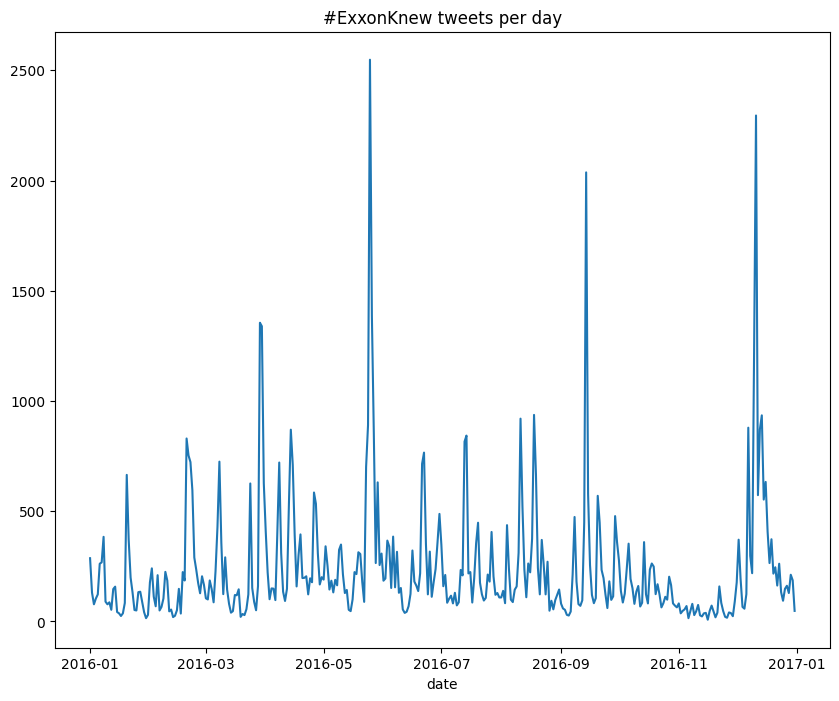

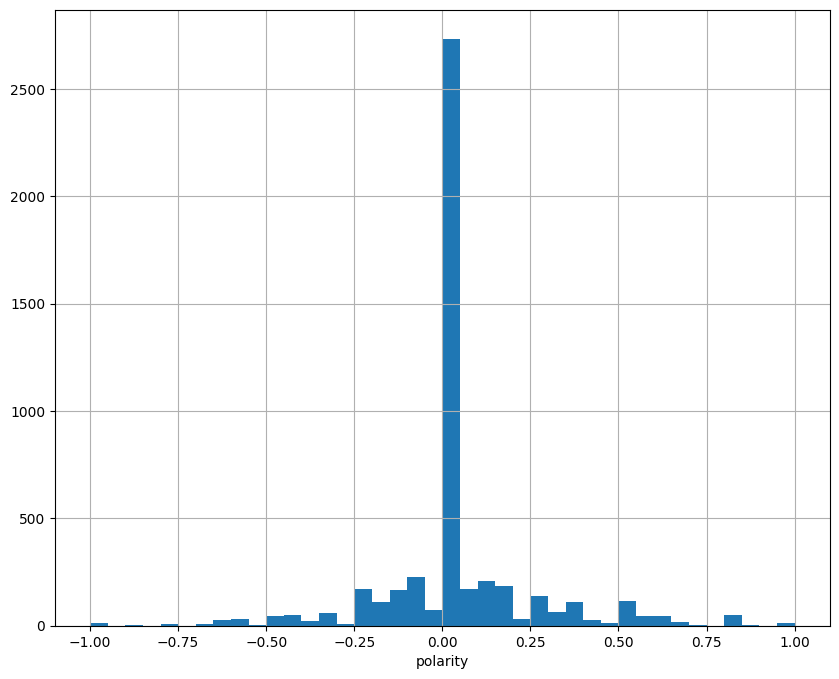

/tmp/ipykernel_3909/4228516315.py:60: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  sample['month'] = sample['created_at'].dt.to_period('M')


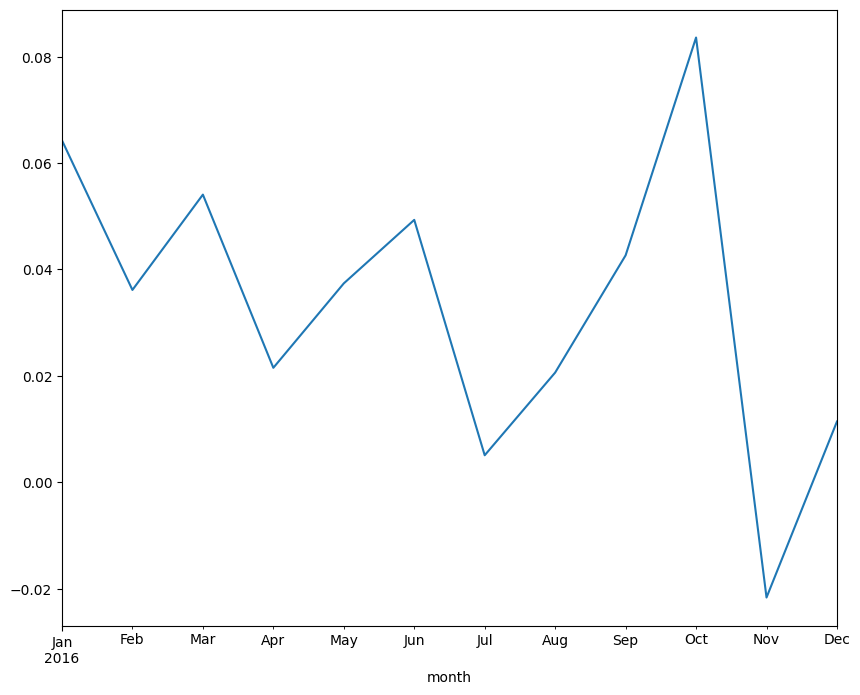

- RT @GeoffreySupran: BREAKING &amp; AWFUL: @theAGU doubles-down on taking Exxon $. No explanation whatsoever. #ExxonKnew https://t.co/wt2KKCcxUd… 

- RT @ClimateTruthOrg: Disgusted by Exxon-funded GOP reps on @HouseScience? Sign on &amp; stand with Senators fighting #WebOfDenial. #ExxonKnew h… 

- RT @350: This is disgusting: Exxon CEO's salary = 500x the median U.S. household income. https://t.co/BwnmfQa3tR #ExxonKnew https://t.co/V9… 

- RT @ClimateTruthOrg: Disgusted by Exxon-funded GOP reps on @HouseScience? Sign on &amp; stand with Senators fighting #WebOfDenial. #ExxonKnew h… 

- RT @ClimateSciWatch: REPORT: @exxonmobil's climate record is terrible https://t.co/1Orvohb8pf #ExxonKnew #OM2016 https://t.co/0zHFxcerpH 

- RT @rahmstorf: Excellent commentary by leading climate scientists: AGU Should Sever Its Ties with ExxonMobil https://t.co/ev4NsqT8Ay #Exxon… 

- .@insideclimate's excellent cover-up reveals what #exxonknew about #climatechange in detail.

https://t.co/WJ7ayUNcsL ht

In [46]:
tweets=pd.read_csv('https://storage.googleapis.com/qm2/wk4/Exxon_tweets_clean.csv')
tweets

#sense check
tweets.info()                               # column types and missing values
tweets['lang'].value_counts().head(10)      # which languages?
tweets['latitude'].notna().sum()            # how many tweets have a location?

#some of the author ID are damaged - exponentials...
tweets['author_id']=tweets['author_id'].astype(str)
tweets.info()

# lang = qme means the tweets are only links/media, no real text
# lang = und means undetermined.
# location almost always NaN indicates that few people share their location
# hence mapping the tweets would not be representative.

# we can look at the busiest times for tweets...
# We add errors='coerce' to bypass non-datetime values (like ID numbers) in this column
tweets['created_at'] = pd.to_datetime(tweets['created_at'], errors='coerce')
tweets['date'] = tweets['created_at'].dt.date

daily = tweets.dropna(subset=['created_at']).groupby('date').size()
daily.plot()
plt.title('#ExxonKnew tweets per day')
plt.show()

daily.sort_values(ascending=False).head(10)   # the busiest days

# can look at why there are spikes at particular days - look at the news

# proportion that are retweets, not original
tweets['is_retweet'] = tweets['text'].astype(str).str.startswith('RT @')
tweets['is_retweet'].mean()     # share of tweets that are retweets

#most retweeted or tweeting accounts
# accounts that get retweeted the most
retweeted = tweets['text'].astype(str).str.extract(r'^RT @(\w+):')[0]
retweeted.value_counts().head(15)

# accounts that tweet the most
tweets['author_id'].value_counts().head(10)

# other hashtags used
hashtags = tweets['text'].astype(str).str.lower().str.findall(r'#\w+').explode()
hashtags.value_counts().head(20)

# sentiment on a sample of the tweets
sample = tweets[tweets['lang'] == 'en'].sample(5000, random_state=1).copy()

# run the pipeline on all sampled tweets at once (faster than one at a time)
docs = list(nlp.pipe(sample['text']))
sample['polarity'] = [d._.blob.polarity for d in docs]
sample['subjectivity'] = [d._.blob.subjectivity for d in docs]

sample['polarity'].hist(bins=40)
plt.xlabel('polarity'); plt.show()

# sentiment over time, by month
sample['month'] = sample['created_at'].dt.to_period('M')
sample.groupby('month')['polarity'].mean().plot()
plt.show()

for t in sample.sort_values('polarity')['text'].head(5):        # most negative
    print('-', t, '\n')
for t in sample.sort_values('polarity')['text'].tail(5):        # most positive
    print('-', t, '\n')

### Sentiment Analysis

Sentiment analysis is the computational study of people's opinions, sentiments, emotions, appraisals, and attitudes towards entities such as products, services, organizations, individuals, issues, events, topics, and their attributes. Let's study the sentiment of the tweets in this dataset.

[spacytextblob](https://spacytextblob.netlify.app/) performs sentiment analysis using the TextBlob library. Adding spacytextblob to a spaCy nlp pipeline creates a new extension attribute for the Doc.

The `._.blob` attribute contains all of the methods and attributes that belong to the `textblob.TextBlob` class. Some of the common methods and attributes include:

1. `._.blob.polarity`: a float within the range [-1.0, 1.0].
2. `._.blob.subjectivity`: a float within the range [0.0, 1.0] where 0.0 is very objective and 1.0 is very subjective.
3. `._.blob.sentiment_assessments.assessments`: a list of polarity and subjectivity scores for the assessed tokens.

Let's run sentiment analysis on a single tweet:

In [26]:
# grab the 130th row in the dataframe and select the text of the tweet
text=tweets.iloc[130]['text']

# apply the NLP pipeline to this text.
doc = nlp(text)

print(text)
print('Polarity: ', doc._.blob.polarity)
print('Subjectivity: ', doc._.blob.subjectivity)
print('Assessments: ', doc._.blob.sentiment_assessments.assessments)

RT @Exxon_Knew: Stop saying #Tillerson is good on climate. He leads the oil company WORST on climate #ExxonKnew via @jacobwe https://t.co/P…
Polarity:  -0.15000000000000002
Subjectivity:  0.8
Assessments:  [(['good'], 0.7, 0.6000000000000001, None), (['worst'], -1.0, 1.0, None)]


We can see that the model has deemed this tweet to be expressing negative sentiment: it has a polarity of -0.15. It also deems this to be a pretty subjective tweet, with a subjectivity score of 0.8. It does indeed appear to be expressing a subjective opinion. Finally, we can see which words are leading to this assessment. The word "good" is leading to a 0.7 increase in the polarity score, and a 0.6 increase in the subjectivity score. The word "worst" is leading to a -1 change polarity, and a +1 change in subjectivity. The overall scores are weighted averages of these values. Though these scores do roughly align with the actual sentiment of this tweet, **ALWAYS** pay attention to whats going on inside of your sentiment analysis pipeline. Even though the overall sentiment score here is negative, it should probably be even more negative; the algorithm picked up on the word "good" in this tweet, and this improved the polarity score by 0.7. But the context in which "good" was uttered in this tweet is actually negative! the person is saying "stop saying #Tillerson is good on climate"-- this is expressing negative sentiment!

---


# Does shareholder pressure lead to green investment?

We've seen that shareholders press Exxon on climate change. But does that pressure change what oil companies actually *do*? [Green, Hadden, Hale & Mahdavi (2022)](https://doi.org/10.1080/09692290.2021.1946708) asked this about the ten biggest oil companies. They measured shareholder pressure as the number of **climate resolutions** filed against each firm each year: formal proposals (like "report on how a 2°C world would affect our business") that all shareholders vote on.

We'll test it with two datasets for the same ten firms, 2004–2019 (sources in the [data folder](https://github.com/oballinger/BASC0005/tree/main/data/w04)):

- the number of climate resolutions voted on at each firm's annual meeting
- the number of **green patents** each firm filed: patents for climate-change mitigation technology (class "Y02"). A patent shows a firm spent money on green research. It is not the same as building wind farms, but it is a good sign of green investment.

In [27]:
# load the two datasets
resolutions = pd.read_csv('https://oballinger.github.io/BASC0005/data/w04/climate_resolutions.csv')
patents = pd.read_csv('https://oballinger.github.io/BASC0005/data/w04/green_patents.csv')

# merge them, so each row is one firm in one year
firms = resolutions.merge(patents, on=['firm', 'year'])
firms.head()

,firm,year,n_climate_resolutions,n_patents,n_green_patents
0,BP,2004,0.0,34,10
1,BP,2005,0.0,34,11
2,BP,2006,0.0,48,19
3,BP,2007,0.0,47,13
4,BP,2008,0.0,47,13


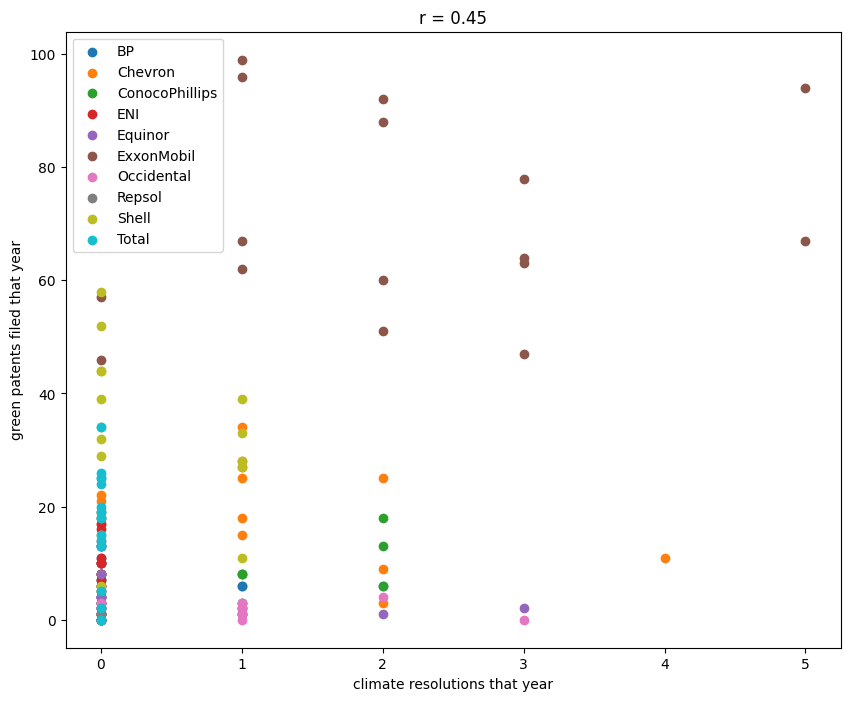

In [28]:
# plot each firm in a different colour
for firm, d in firms.groupby('firm'):
    plt.scatter(d['n_climate_resolutions'], d['n_green_patents'], label=firm)

plt.xlabel('climate resolutions that year')
plt.ylabel('green patents filed that year')
plt.title('r = ' + str(round(firms['n_climate_resolutions'].corr(firms['n_green_patents']), 2)))
plt.legend()
plt.show()

A positive correlation: more pressure, more green patents! But look at which firm is in the top right. Exxon is by far the biggest company in the sample: it files the most patents of *every* kind, and it attracts the most resolutions. Remember the lesson from counting climate mentions: **counts are not rates**. Let's use the green *share* of each firm's patents instead:

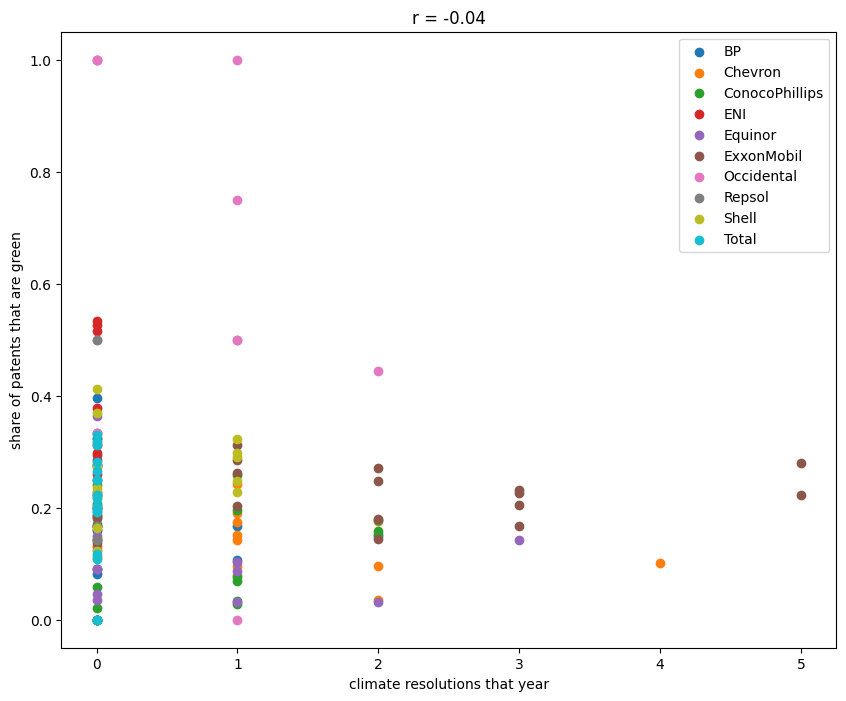

0      0.395833
1      0.276596
2      0.276596
3      0.200000
4      0.166667
         ...   
155    0.000000
156    0.142857
157    0.500000
158         NaN
159         NaN
Name: green_share, Length: 160, dtype: float64


In [48]:
# the share of each firm's patents that are green
firms['green_share'] = firms['n_green_patents'] / firms['n_patents']

for firm, d in firms.groupby('firm'):
    plt.scatter(d['n_climate_resolutions'], d['green_share'], label=firm)

plt.xlabel('climate resolutions that year')
plt.ylabel('share of patents that are green')
plt.title('r = ' + str(round(firms['n_climate_resolutions'].corr(firms['green_share']), 2)))
plt.legend()
plt.show()

# checking the points that sit at 0 and 1
# these are Occidental and Repsol and ... their number of patents?
# try to understand why the shares are 'jumpy'
firms[(firms['green_share'] == 0) | (firms['green_share'] == 1)]
# I don't really understand the results...
# Some file double figure patents but none green so zero
# Some file as many patents as green hence 1...

#Does pressure this year go with more green patents two years later
analysis = firms.groupby('firm')['green_share'].shift(-2)
print(analysis)

---

### Exercise

1. What happened to the correlation when we switched from counts to shares? Which result do you believe, and why?
2. Green et al. found that climate resolutions were "weakly negatively correlated with overall decarbonization (−0.14)", and suggest that "shareholder advocates tend to target the worst offenders." Explain in your own words why that would make it hard to tell whether pressure *works*.
3. Some points sit at exactly 0 or 1. Which firms are they? Check their `n_patents`: why are their shares so jumpy?
4. Patents take time. Does pressure this year go with more green patents two years later? (Hint: `firms.groupby('firm')['green_share'].shift(-2)` gives each firm's green share two years ahead.)

---

Complete change in correlation.
Believe the share rate as it accounts for context. R changes from positive 0.45 to negative 0.04...
There is no longer a density of ExxonMobil at the top, it is now Occidental, ExonnMobil is now in the lower region, Occidental was previously almost at zero.

# Assessed Question

The URL below contains the speaker turns from Exxon's annual shareholder meetings, 2004-2019: one row per speaker turn, like the `speaker_file` dataframe we built above, but for all the meetings. The columns are `date`, `year`, `title`, `name`, `affiliation`, `speaker` (`Exxon` for company executives, `Investor` for shareholders), `words` (number of words in the turn) and `text`.

https://oballinger.github.io/BASC0005/data/assessed/w04_exxon_agm_turns.csv

Note that the file may have been corrupted; some values or labels may be wrong, so make sure to sense-check your data before answering.

**QUESTION: Measure shareholder pressure on fracking: for each year, count mentions of "fracking" and "hydraulic fracturing" (case-insensitive) in investor turns, divided by the number of words investors spoke that year (mentions per 1,000 words). In which year was shareholder pressure on fracking highest?**

Keep a note of your answer: you will enter it in the Problem Set Answers quiz on Moodle in December.

Shape (rows, columns): (690, 8)
Columns: ['date', 'year', 'title', 'name', 'affiliation', 'speaker', 'words', 'text']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 690 entries, 0 to 689
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   date         690 non-null    datetime64[ns]
 1   year         690 non-null    int64         
 2   title        690 non-null    object        
 3   name         690 non-null    object        
 4   affiliation  328 non-null    object        
 5   speaker      690 non-null    object        
 6   words        690 non-null    int64         
 7   text         690 non-null    object        
dtypes: datetime64[ns](1), int64(2), object(5)
memory usage: 43.3+ KB

Missing values per column:


,0
date,0
year,0
title,0
name,0
affiliation,362
speaker,0
words,0
text,0


,date,year,name,speaker,words,text
0,2004-05-26,2004,PATRICK MULVA,Exxon,1117,Good morning. I'd like to cover several aspect...
1,2004-05-26,2004,LEE RAYMOND,Exxon,1696,"I would, now, like to make a few comments abou..."
2,2004-05-26,2004,REX TILLERSON,Exxon,2872,"Good morning. As you just saw, the world's dem..."
3,2004-05-26,2004,LEE RAYMOND,Exxon,430,"Now, I would like to turn to the formal busine..."
4,2004-05-26,2004,LEE RAYMOND,Exxon,3,Number two please.


,year,name,speaker,words,text
5,2004,ANDREW LOGAN,Investor,367,Thank you. My name is Andrew Logan (ph). I am ...
7,2004,ROBERT MONK,Investor,29,I am Robert Monk. I'd like to know if I am at ...
9,2004,PETER ALTMAN,Investor,302,"I am Peter Altman, national coordinator of Cam..."
11,2004,TRACY LAMBERT,Investor,330,"Thank you, Mr. Raymond. My name is Tracy Lambe..."
13,2004,PAUL DRIESSEN,Investor,329,"I am Paul Driessen, Senior Policy Advisor for ..."


,year,name,fracking,hydraulic_fracturing
5,2004,ANDREW LOGAN,0,0
7,2004,ROBERT MONK,0,0
9,2004,PETER ALTMAN,0,0
11,2004,TRACY LAMBERT,0,0
13,2004,PAUL DRIESSEN,0,0


,fracking,hydraulic_fracturing,words,total_fracking_mentions,fracking_rate
year,,,,,
2004,0,0,17042,0,0.00
2007,0,0,11084,0,0.00
2010,0,4,10518,4,0.38
2011,3,14,13532,17,1.26
2013,5,7,35112,12,0.34
2014,0,2,6573,2,0.30
2015,1,4,8192,5,0.61
2016,3,1,8640,4,0.46
2017,0,0,4189,0,0.00


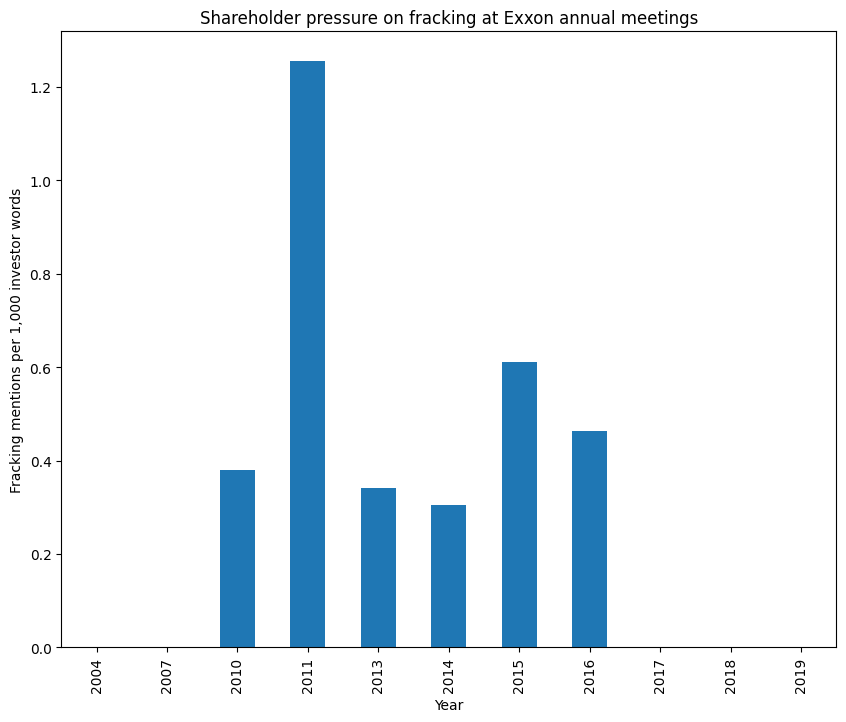

Shareholder pressure on fracking was highest in 2011, with 1.26 mentions per 1,000 investor words.


In [19]:
# %pip install pypdf spacytextblob

import io
import re
import requests
import spacy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pypdf import PdfReader
from spacytextblob.spacytextblob import SpacyTextBlob

plt.rcParams['figure.figsize'] = (10., 8.)
nlp = spacy.load("en_core_web_sm")
nlp.add_pipe('spacytextblob')


# -------------------------
# LOAD DATA
# -------------------------

url = "https://oballinger.github.io/BASC0005/data/assessed/w04_exxon_agm_turns.csv"

investigate = pd.read_csv(url)

# -------------------------
# SENSE-CHECK FUNCTIONS
# -------------------------

def check(investigate, cols=None, n=5, info=False, missing=False, counts=None): #use boolean operators
    """
    Quick sense check of a DataFrame.

    investigate : DataFrame to check
    cols        : list of columns to show
    n           : number of rows to show
    info        : True shows column types and non-null counts
    missing     : True shows missing values per column
    counts      : column name to show value counts for
    """

    print("Shape (rows, columns):", investigate.shape)
    print("Columns:", list(investigate.columns))

    if info:
        investigate.info()

    if missing:
        print("\nMissing values per column:")
        display(investigate.isna().sum())

    if counts is not None:
        print(f"\nValue counts for '{counts}':")
        display(investigate[counts].value_counts())

    if cols is None:
        display(investigate.head(n))
    else:
        display(investigate[cols].head(n)) #missing values for affiliations - not relevant


def check_word_counts(investigate):
    """
    Compare the supplied 'words' column
    with a simple word count calculated from 'text'.
    """

    investigate['word_check'] = investigate['text'].str.split().apply(len)

    display(investigate[['words', 'word_check']].head(20))

    investigate['word_difference'] = (investigate['words'] - investigate['word_check'])

    print("Difference between given and calculated word counts:")

    display(investigate['word_difference'].value_counts())

# -------------------------
# BASIC CLEANING
# -------------------------

investigate['date'] = pd.to_datetime(investigate['date']) #from object to date time

check(investigate, cols=['date', 'year', 'name', 'speaker', 'words', 'text'], info=True, missing=True)

# -------------------------
# FILTER FOR INVESTOR TURNS
# -------------------------

investors = investigate[investigate['speaker'] == 'Investor'].copy()

display(investors[['year', 'name', 'speaker', 'words', 'text']].head())


# -------------------------
# COUNT FRACKING MENTIONS
# -------------------------

investors['fracking'] = investors['text'].apply(lambda x: str(x).lower().count('fracking'))

investors['hydraulic_fracturing'] = investors['text'].apply(lambda x: str(x).lower().count('hydraulic fracturing'))

display(investors[['year', 'name', 'fracking', 'hydraulic_fracturing']].head())

# -------------------------
# GROUP BY YEAR
# -------------------------

annual = investors.groupby('year')[['fracking', 'hydraulic_fracturing', 'words']].sum() #merges dataset

# total mentions of both terms
annual['total_fracking_mentions'] = (annual['fracking']+ annual['hydraulic_fracturing'])

# mentions per 1,000 investor words
annual['fracking_rate'] = (annual['total_fracking_mentions']/ annual['words']* 1000)

display(annual.round(2)) # for readability

# -------------------------
# SHAREHOLDER PRESSURE...?
# -------------------------
#shareholder pressure on fracking = how frequently investors mention fracking, relative to how much investors spoke overall that year
# hence it has just been defined (a proxy)
# to visualise
annual['fracking_rate'].plot(kind='bar')

plt.xlabel('Year')
plt.ylabel('Fracking mentions per 1,000 investor words')
plt.title('Shareholder pressure on fracking at Exxon annual meetings')
plt.show()

# year that is highest - index
max_year = annual['fracking_rate'].idxmax()
max_rate = annual['fracking_rate'].max()

print(f"Shareholder pressure on fracking was highest in {max_year}, " f"with {max_rate:.2f} mentions per 1,000 investor words.")

## (Optional) Extension: tense

spaCy also records the **tense** of each verb in `token.morph`. Is Exxon talking about climate change in the past ("we have invested") or the future ("we will reduce")? The cell below counts past- and present-tense verbs in the first 200 climate change sentences.

In [20]:
# count the tense of every verb in the first 200 climate change sentences
tenses = []
for doc in nlp.pipe(climate_sentences[:200]):
    for token in doc:
        tenses += token.morph.get('Tense')   # e.g. ['Past'], or [] for words that aren't verbs

pd.Series(tenses).value_counts()

NameError: name 'climate_sentences' is not defined

English has no future tense ending, so "will reduce" shows up as the word "will" plus a verb with no tense. Try counting how often "will" appears in the climate sentences, and compare with the sentences about earnings or dividends. Is Exxon more forward-looking about climate than about money?

In [32]:
# your code here